# Die Gausssche Normalverteilung

[Vorlesungsaufzeichnung Normalverteilung](https://media.hhu.de/channel/video/data-science-vl-8-normalverteilung-2025/a5265a7f0515cc225d54652f5a8a8d0d/167)

## Approximation der Binomialverteilung

Betrachten wir eine Folge von Bernoulli-verteilten Zufallsvariablen $X_i$ mit gleichem Parameter $p$ und $S_n := \sum_{i=1}^n X_i$ die Summe über die ersten $n$ davon, so wissen wir aus dem Kapitel [Wichtigste diskrete Verteilungen](wichtigste-diskrete-verteilungen.ipynb) bereits, dass $S_n \sim \operatorname{Bin}(n,p)$, also dass diese Summe binomialverteilt ist. Erinnerung: Das bedeutet, die pmf von $S_n$ ist $p(k) = \binom{n}{k}p^k(1-p)^{n-k}$.

Für die konkreten Werte $n=100,\ p=0.4$ sieht ein Histogramm von $100000$ Samples etwa so aus:


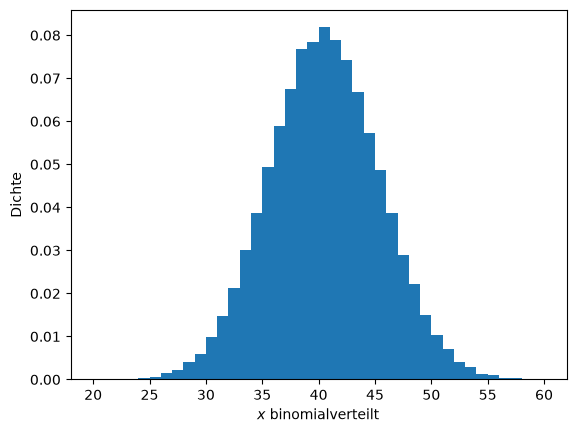

In [1]:
import numpy as np
from scipy.stats import binom, norm
from matplotlib import pyplot as plt
np.random.seed(123123)
binom_samples = binom.rvs(n=100,
                          p=0.4,
                          size=100000)
plt.hist(binom_samples, bins=40, density=True)
plt.xlabel("$x$ binomialverteilt")
plt.ylabel("Dichte")
plt.show()

Da diese Form für große Stichproben stets so aussieht, unabhängig von $p$ (probieren Sie das aus!), könnte man sich vorstellen, dass die Verteilung sich approximieren lässt mit Hilfe einer Funktion, die leichter zu berechnen ist als Binomialkoeffizienten $\binom{n}{k} = \frac{n!}{k!(n-k)!}$.

**Nebenbemerkung**: Tatsächlich gibt es zur Approximation der Fakultät auch die *Stirling-Formel*

$$
n! \approx \sqrt{2\pi n} {\left(\frac{n}{e}\right)}^n
$$

Was uns für Binomialkoeffizienten direkt liefert: $\binom{n}{k} = \frac{\sqrt{n}}{\sqrt{2\pi}\sqrt{k}\sqrt{n-k} }  \frac{n^n}{k^k {\left(n-k\right)}^{(n-k)} }$

Damit lässt sich nun (auch wenn es nicht ganz einfach ist) eine Approximation zeigen:

$$
P(S_n = k) = \binom{n}{k}p^k(1-p)^{n-k} \sim
\frac{1}{\sqrt{np(1-p)}} \frac{1}{\sqrt{2\pi}} e^{-\frac{x^2}{2}} \quad \text{ für } n \to \infty
$$

wobei für $x$ auf der rechten Seite die Folge $x=x_n$ mit
$x_n = x_n(k) = \frac{k-np}{\sqrt{np(1-p)}}$ eingesetzt werden muss. Das Symbol $\sim$ bedeutet: asymptotisch gleich, d.h. der Quotient konvergiert gegen $1$.

Diese Approximation ist insofern hilfreich, als dass wir nun die Funktion $e^{-\frac{x^2}{2}}$ tabellieren können und konkrete Werte für gewisse $n,p$ ablesen können. Das ist wesentlich effizienter, als Binomialkoeffizienten auszurechnen. Die ganze Beobachtung heißt auch **Satz** von deMoivre-Laplace und soll uns zunächst als Motivation dienen, die Funktion $e^{-\frac{x^2}{2}}$ näher zu untersuchen.

## Ein Integral

Um aus der Funktion $e^{-\frac{x^2}{2}}$ eine Wahrscheinlichkeitsdichte zu machen, muss das Integral $1$ ergeben. Wir berechnen, weil es danach sehr nützlich wird, gleich ein etwas allgemeineres Integral:

:::{admonition} Lemma
Sei $v \in \mathbb{R}$ und $v > 0$. Dann gilt

$$
\int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx = \sqrt{2\pi v}.
$$
:::

:::{admonition} Beweis
Da auf der rechten Seite eine Quadratwurzel steht, bietet es sich an, beide Seiten der Gleichung zu quadrieren. Wir formen die linke Seite dann weiter um, bis wir ein Integral über $\mathbb{R}^2$ in Polarkoordinaten transformieren können und dann nach einer Substitution leicht Stammfunktionen bestimmen können:

$$
\begin{aligned}
  & {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx \right)}^2 \\
 =& {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} dx \right)}{\left( \int_{-\infty}^\infty e^{-\frac{y^2}{2v}} dy \right)} \\
 =& \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} {\left( \int_{-\infty}^\infty e^{-\frac{y^2}{2v}} dy \right)} dx \\
 =& \int_{-\infty}^\infty {\left( \int_{-\infty}^\infty e^{-\frac{x^2}{2v}} e^{-\frac{y^2}{2v}} dy \right)} dx \\
 =& \int_{-\infty}^\infty {\left( \int_{-\infty}^\infty e^{-\frac{x^2+y^2}{2v}} dy \right)} dx \\
 =& \int_{\mathbb{R}^2} e^{-\frac{x^2+y^2}{2v}} d(x,y) \\
 =& \int_{0}^\infty \int_{0}^{2\pi} r e^{-\frac{r^2}{2v}} d\phi dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}}  \int_{0}^{2\pi} d\phi dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}} [\phi]_0^{2\pi} dr \\
 =& \int_{0}^\infty r e^{-\frac{r^2}{2v}} 2\pi dr \\
 =& 2\pi \int_{0}^\infty e^{-\frac{r^2}{2v}} r dr \\
 =& 2\pi \int_{0}^{-\infty} e^u (-v)du \\
 =& 2\pi v \int_{-\infty}^{0} e^u du \\
 =& 2\pi v [e^u]_{-\infty}^{0} \\
 =& 2\pi v.
\end{aligned}
$$
:::

Da Integrale in der Statistik häufiger vorkommen, ist es nicht ganz verkehrt, sich bei dieser Rechnung klar zu machen, was genau warum in jedem Schritt passiert.

## Die eindimensionale Normalverteilung

:::{admonition} Definition
Seien $\mu,\sigma \in \mathbb{R}$ mit $\sigma > 0$. Dann heißt die Verteilung mit Dichtefunktion

$$
\phi(x) = \phi(x,\mu,\sigma) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

*Normalverteilung* und wir schreiben für eine reelle Zufallsvariable $X$ mit dieser Verteilung auch $X \sim \mathcal{N}(\mu,\sigma^2)$.
:::

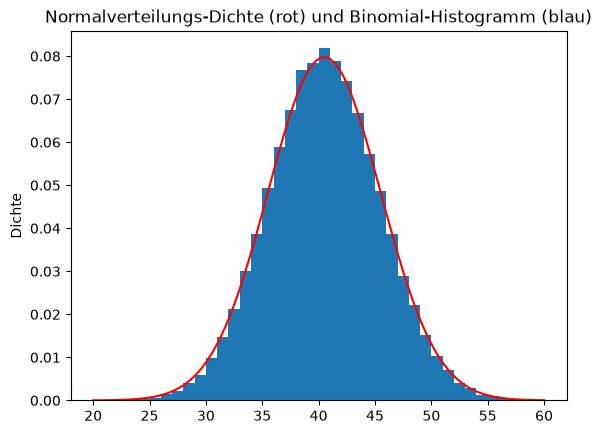

In [2]:
x = np.linspace(20,60,100)
plt.hist(binom_samples, bins=40, density=True)
plt.plot(x, norm(loc=40.5, scale=5).pdf(x), color="red")
plt.ylabel('Dichte')
plt.title('Normalverteilungs-Dichte (rot) und Binomial-Histogramm (blau)')
plt.show()

:::{admonition} Proposition
Wenn $X \sim \mathcal{N}(\mu,\sigma^2)$, so ist $\mathbb{E}(X) = \mu$ und $\mathbb{V}(X) = \sigma^2$.
:::

:::{admonition} Beweis
Wir setzen die Dichte für $X$ in die Formel für $\mathbb{E}(X)$ ein und transformieren das Integral über $x$ in ein Integral über $x + \mu$:

$$
\begin{aligned}
\mathbb{E}(X) &= \int_{-\infty}^{\infty} x\phi(x) dx \\
              &=  \int_{-\infty}^{\infty} x \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \int_{-\infty}^{\infty} x e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \int_{-\infty}^{\infty} (x+\mu) e^{-\frac{x^2}{2\sigma^2}} dx \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \left( \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) + \mu \left( \int_{-\infty}^{\infty} e^{-\frac{x^2}{2\sigma^2}} dx \right) \right) \\
              &= \frac{1}{\sigma\sqrt{2\pi}} \left( \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) + \mu \sigma\sqrt{2\pi} \right) \\
              &= \mu + \frac{1}{\sigma\sqrt{2\pi}} \left( \int_{-\infty}^{\infty} x e^{-\frac{x^2}{2\sigma^2}} dx \right) = \mu.\\
\end{aligned}
$$

Der Ausdruck nach dem $\mu +$ ist einfach $0$, denn die Funktion ist punktsymmetrisch um $0$ (der Faktor $x$ ist offensichtlich eine ungerade Funktion, der andere Faktor hängt nur von $|x|$ ab).

Genau so kann man bei der Varianz verfahren, indem man diesen Ausdruck vereinfacht:

$$
\begin{aligned}
\mathbb{V}(X) &= \int_{-\infty}^{\infty} x^2\phi(x) dx  - {\left( \mathbb{E}(X) \right)}^2 \\
              &= \int_{-\infty}^{\infty} x^2\frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}} dx - \mu^2.
\end{aligned}
$$
:::

:::{admonition} Definition
Man nennt eine Zufallsvariable mit $X \sim \mathcal{N}(0,1)$ auch *standardnormalverteilt*
:::

:::{admonition} Proposition
Wenn $X \sim \mathcal{N}(\mu,\sigma^2)$, so ist $\frac{X - \mu}{\sigma} \sim \mathcal{N}(0,1)$.
:::


:::{admonition} Beweis
**Idee:**
Es ist sofort klar, dass $\mathbb{E}(X-\mu) = 0$ und dass $\mathbb{V}\left(\frac{X-\mu}{\sigma}\right) = 1$.
Weniger klar ist, dass die neue Zufallsvariable tatsächlich normalverteilt ist. Das lässt sich z.B. mit der  Momenterzeugendenfunktion beweisen.
:::

Die Standardisierung ist ein Spezialfall einer allgemeineren Aussage, die man ständig braucht:

:::{admonition} Proposition
Ist $X \sim \mathcal{N}(\mu,\sigma^2)$ und sind $a \neq 0$, $b \in \mathbb{R}$, so ist

$$
aX + b \sim \mathcal{N}\left( a\mu + b,\ a^2\sigma^2 \right).
$$

Die Normalverteiltheit bleibt also unter affin-linearen Transformationen erhalten.
:::

:::{admonition} Beweis
**Idee:** Erwartungswert und Varianz folgen aus den Rechenregeln des Kapitels [Erwartungswert und Varianz](erwartungswert.md). Dass die Form erhalten bleibt, sieht man an der Dichte: Für eine Zufallsvariable $X$ mit Dichte $p_X$ hat $Y = aX+b$ die Dichte

$$
p_Y(y) = \dfrac{1}{|a|}\, p_X\!\left( \dfrac{y-b}{a} \right)
$$

(die Transformationsformel: Der Faktor $\frac{1}{|a|}$ sorgt dafür, dass das Integral wieder $1$ ergibt). Setzt man hier die Normalverteilungsdichte ein, steht im Exponenten $-\frac{((y-b)/a - \mu)^2}{2\sigma^2} = -\frac{(y - (a\mu+b))^2}{2a^2\sigma^2}$, und der Vorfaktor wird $\frac{1}{|a|\sigma\sqrt{2\pi}}$ — das ist genau die Dichte von $\mathcal{N}(a\mu+b, a^2\sigma^2)$.
:::

Zwei Spezialfälle lohnen das Merken. Mit $a = \frac1\sigma$ und $b = -\frac\mu\sigma$ erhält man die Standardisierung von oben. Und umgekehrt: Ist $Z \sim \mathcal{N}(0,1)$, so ist $\sigma Z + \mu \sim \mathcal{N}(\mu,\sigma^2)$ — jede Normalverteilung entsteht also aus der Standardnormalverteilung durch Strecken und Verschieben. Genau so erzeugt man sie auch am Rechner: `mu + sigma * rng.standard_normal(n)` braucht nur einen einzigen Zufallszahlengenerator für alle Normalverteilungen. Im Kapitel [Multivariate Normalverteilung](multivariate-normalverteilung.ipynb) ist das der Ausgangspunkt: Dort wird dieselbe Konstruktion mit einer Matrix statt einer Zahl durchgeführt.

Außerdem nutzen wir, dass die Summe von unabhängigen Zufallsvariablen mit Dichten $f,g$ selbst wieder eine Dichte hat, nämlich die *Faltung* $f \ast g$. Anstatt das rigoros einzuführen und zu beweisen, benutzen wir es weiter unten für die Summe zweier Normalverteilungen.

:::{admonition} Satz
Unter allen **stetigen** Verteilungen reeller Zufallsvariablen $X$ mit **Träger ganz $\mathbb{R}$** und festem Erwartungswert $\mu = \mathbb{E}(X)$ und fester Varianz $\sigma^2 = \mathbb{V}(X)$ ist die Normalverteilung diejenige mit der maximalen Entropie.
:::

Um diesen Satz überhaupt präzise formulieren zu können, benötigen wir einen Entropiebegriff für stetige Verteilungen. Anstatt das jetzt zu tun, wollen wir uns später damit beschäftigen, wenn wir auch relative Entropie, die stetige Version davon und Likelihood diskutieren.

:::{admonition} Proposition
Sind $X \sim \mathcal{N}(\mu_1, \sigma_1^2)$ und $Y \sim \mathcal{N}(\mu_2, \sigma_2^2)$ unabhängig, so ist $X + Y \sim \mathcal{N}(\mu_1 + \mu_2,\ \sigma_1^2 + \sigma_2^2)$. Allgemeiner ist jede Linearkombination $aX + bY$ wieder normalverteilt, mit Erwartungswert $a\mu_1 + b\mu_2$ und Varianz $a^2\sigma_1^2 + b^2\sigma_2^2$.

**Ohne Beweis**
:::

Erwartungswert und Varianz folgen aus den Rechenregeln im Kapitel [Erwartungswert und Varianz](erwartungswert.md); das Bemerkenswerte ist, dass auch die *Form* erhalten bleibt — die Summe ist nicht nur irgendeine Verteilung mit diesen Momenten, sondern wieder eine Glockenkurve. Das ist keineswegs selbstverständlich: Die Summe zweier gleichverteilter Variablen ist dreiecksverteilt, nicht gleichverteilt. Man sagt, die Normalverteilung ist *stabil unter Faltung*. Im Kapitel zur [multivariaten Normalverteilung](multivariate-normalverteilung.ipynb) sehen wir die Verallgemeinerung: Dort gilt dasselbe auch für *abhängige* $X, Y$, sobald sie gemeinsam normalverteilt sind, mit einem zusätzlichen Kovarianzterm in der Varianz.

Wichtig ist aber die Take-Home-Message des Satzes: Wenn über eine stetige Verteilung reeller Zahlen außer Erwartungswert und Varianz nichts bekannt ist, dann ist die entprechende Normalverteilung die vernünftigste Annahme. In diesem Sinne ist die Normalverteilung ein guter stetiger Ersatz für die diskrete Gleichverteilung, aber nun auf ganz $\mathbb{R}$ (die Normalverteilung hat Träger $\mathbb{R}$).

Die Einschränkung auf den Träger $\mathbb{R}$ ist dabei keine Formalie, sondern die eigentliche Modellannahme. Kennt man den Träger genauer, ist eine andere Verteilung die mit maximaler Entropie — und damit die vernünftigste Annahme:

| Träger | was sonst bekannt ist | Verteilung mit maximaler Entropie |
|---|---|---|
| $\{1,\dots,n\}$ | nichts | diskrete Gleichverteilung, $p(k) = \frac1n$ |
| $[a,b]$ | nichts | stetige Gleichverteilung, $f(x) = \frac{1}{b-a}$ |
| $[0,\infty)$ | Erwartungswert $\mu$ | Exponentialverteilung, $f(x) = \lambda e^{-\lambda x}$ mit $\lambda = \frac1\mu$ |
| $\mathbb{R}$ | Erwartungswert und Varianz | Normalverteilung |
| $[a,b]$ | Erwartungswert und Varianz | gestutzte Normalverteilung (`scipy.stats.truncnorm`) |

Die Steckbriefe der drei stetigen Verteilungen stehen im Kapitel [Wichtigste stetige Verteilungen](wichtigste-stetige-verteilungen.ipynb), die diskrete Gleichverteilung im Kapitel [Erwartungswert und Varianz](erwartungswert.md). Die gestutzte Normalverteilung ist genau das, wonach es klingt: eine Normalverteilung, deren Dichte außerhalb von $[a,b]$ auf $0$ gesetzt und innerhalb neu normiert wird. Man braucht sie, wenn eine Größe von Natur aus beschränkt ist — Anteile zwischen $0$ und $1$, Messwerte an der Anzeigegrenze eines Geräts — und ein Normalverteilungsmodell sonst Wahrscheinlichkeitsmasse dort verteilen würde, wo es gar keine Werte geben kann.

Das Muster dahinter ist immer dasselbe: Maximale Entropie heißt „so wenig zusätzlich annehmen wie möglich“. Was man weiß, geht als Nebenbedingung ein; alles andere überlässt man dem Zufall.


## Der zentrale Grenzwertsatz

:::{admonition} Satz
Wenn $X_i$ eine Folge von identisch verteilten, voneinander unabhängigen (iid = independent identically distributed) Zufallsvariablen mit Erwartungswert $\mathbb{E}(X_i)=0$ und Varianz $\mathbb{V}(X_i)=\sigma^2$ ist,
und wir die skalierte Summe $Z_N := \dfrac{1}{\sigma\sqrt{N}} \sum_{i=1}^N X_i$ (mit $\mathbb{E}(Z_N)=0$ und $\mathbb{V}(Z_N)=1$) betrachten, dann gilt die Konvergenz in Verteilung:

$$
Z_N \xrightarrow{N \to \infty} \mathcal{N}(0,1)
$$
:::

Der Buchstabe $Z$ soll daran erinnern, dass $Z_N$ die auf Erwartungswert $0$ und Varianz $1$ normierte Version der Summe $S_N = \sum_{i=1}^N X_i$ ist, die wir oben für Bernoulli-Variablen betrachtet haben.

Konvergenz in Verteilung heißt, dass die Verteilungsfunktion von $Z_N$ gegen die Verteilungsfunktion einer Standardnormalverteilung konvergiert.

Von diesem Satz gibt es auch Abschwächungen, die gewisse Abhängigkeiten zwischen den $X_i$ erlauben.

:::{admonition} Bemerkung
Wichtig ist der Satz für uns, weil er erlaubt eine Summe unabhängiger Zufallsvariablen mit einer Normalverteilung zu approximieren. Das tritt in der Praxis häufig auf, wenn man Messungen an physikalischen oder technosozialen Systemen vornimmt, die in der Regel von einer langen Liste weitgehend unabhängiger Störeinflüsse beeinträchtigt werden. Diese Summe an Fehlerquellen ist (für eine hinreichend große Zahl an unabhängigen Fehlerquellen) etwa normalverteilt.
:::

Um zwei konkrete Beispiele zu nennen: der Fehler bei der Ortsbestimmung mit GNSS-Systemen wie GPS ist normalverteilt (auch wenn die atmosphärischen Störungen, die den Wert ungenauer machen, nicht normalverteilt sind). Bei der industriellen Fertigung von Bauteilen gibt es ebenfalls im gesamten Produktionsprozess Fehlerquellen, die am Ende zu einer Normalverteilung aufsummieren - deren Varianz man hinreichend klein halten muss, damit das Bauteil seine Aufgabe erfüllen kann. So darf ein Legostein nicht zu stark von einem baugleichen Legostein abweichen, sonst hält das Bauwerk hinterher nicht richtig.

:::{admonition} Bemerkung
**Der Standardfehler.** Die wichtigste Anwendung für uns: Das Mittel $\overline{X}_N$ einer Stichprobe der Größe $N$ ist selbst eine (skalierte) Summe, also für große $N$ näherungsweise normalverteilt, mit Erwartungswert $\mu$ und Standardabweichung $\sigma/\sqrt{N}$. Diese Standardabweichung des Stichprobenmittels heißt **Standardfehler**. Da eine normalverteilte Größe mit Wahrscheinlichkeit $95\,\%$ um weniger als $1{,}96$ Standardabweichungen von ihrem Erwartungswert abweicht, liegt der wahre Erwartungswert in etwa $95\,\%$ aller Stichproben im Intervall $\overline{X}_N \pm 1{,}96\,\sigma/\sqrt{N}$. Das ist schärfer als die Tschebyscheff-Ungleichung aus dem Kapitel [Erwartungswert und Varianz](erwartungswert.md), die für zwei Standardfehler nur $75\,\%$ garantiert, und es ist das Rezept, mit dem das Kapitel [Statistische Tests](statistische-tests.md) von der Stichprobe auf die Population schließt. Beispiel Titanic: Von $314$ Frauen haben $74{,}2\,\%$ überlebt; der Standardfehler dieses Anteils ist $\sqrt{0{,}742 \cdot 0{,}258 / 314} \approx 0{,}025$, das Intervall also etwa $74 \pm 5$ Prozentpunkte.
:::


**Nebenbemerkung**: Man kann außerdem die Geschwindigkeit der Konvergenz abschätzen, und damit in Erfahrung bringen, wie gut die Approximation durch eine Normalverteilung ist:

:::{admonition} Satz von Berry–Esseen
Es existiert eine Konstante $C$ mit $0{,}41 \le C \le 0{,}48$ und der folgenden Eigenschaft:

Wenn $X_i$ eine Folge von iid Zufallsvariablen mit Erwartungswert $0$ und Varianz $\sigma^2$ ist, und außerdem die dritten absoluten Momente $\mathbb{E}|X_i|^3 = \rho < \infty$ existieren,
wir $F_N$ für die kumulative Verteilungsfunktion von $Z_N = \frac{1}{\sigma\sqrt{N}} \sum_{i=1}^N X_i$ schreiben und $\Phi$ für die kumulative Verteilungsfunktion der Standardnormalverteilung $\mathcal{N}(0,1)$, so gilt für alle $N$:

$$
\sup_{x \in \mathbb{R}} \left| F_N(x) - \Phi(x) \right| \ \leq\ \dfrac{C\rho}{\sigma^3 \sqrt{N}}.
$$
:::

Der genaue Wert von $C$ ist nicht bekannt; die angegebenen Schranken sind der Stand der Forschung. Für konkret bekannte $\sigma,\rho$ können wir also stets ein $N$ bestimmen, mit dem die linke Seite beliebig klein wird. Mit anderen Worten: es lässt sich zu jeder gewünschten Genauigkeit berechnen, wie viele der iid Zufallsvariablen man (skaliert) aufaddieren muss, um $Z_N$ mit einer Standardnormalverteilung zu approximieren.

Klar: Wenn der Erwartungswert nicht $0$ ist, lässt sich eine Variante als Korollar beweisen (wie auch beim zentralen Grenzwertsatz), sodass die Konvergenz gegen $\mathcal{N}(\mu,1)$ geht. Wenn man anders reskaliert, auch gegen $\mathcal{N}(\mu,\sigma^2)$. In der Praxis sieht es eher so aus, dass man alle unbekannten Fehlerterme mit einer Normalverteilung modelliert, deren Erwartungswert und Varianz man empirisch schätzt.

## Praxisbeispiel: Der „$N \ge 30$“-Mythos

In vielen Lehrbüchern, Statistik-Kursen und Auswertungsvorschriften steht eine Faustregel: *Ab $N = 30$ darf man mit einer Normalverteilung rechnen.* Diese Regel ist so verbreitet, dass sie selten hinterfragt wird — und sie ist in der Form falsch. Berry–Esseen sagt uns auch, warum.

Die Schranke oben lautet $\frac{C\rho}{\sigma^3\sqrt{N}}$. Darin steht $N$ nur unter einer Wurzel, den Ausschlag gibt der Faktor $\rho/\sigma^3$: das dritte absolute Moment relativ zur dritten Potenz der Standardabweichung, also ein Maß dafür, wie schief die einzelne Zufallsvariable ist. Für eine symmetrische Verteilung ist dieser Faktor klein, für eine schiefe kann er beliebig groß werden — und dann reicht $N = 30$ eben nicht.

Der wichtigste Fall in der Praxis ist ein binäres Merkmal: „Nebenwirkung aufgetreten ja/nein“, „Klick ja/nein“, „überlebt ja/nein“. So ein Merkmal ist Bernoulli-verteilt mit Parameter $p$, und wir können den Faktor ausrechnen. Für $X \sim \operatorname{Bernoulli}(p)$, zentriert auf Erwartungswert $0$, ist

$$
\sigma^2 = p(1-p), \qquad \rho = \mathbb{E}\left|X - p\right|^3 = p(1-p)\left[(1-p)^2 + p^2\right],
$$

also

$$
\dfrac{\rho}{\sigma^3} = \dfrac{(1-p)^2 + p^2}{\sqrt{p(1-p)}}.
$$

Für ein ausgeglichenes Merkmal, $p = 0{,}5$, ist das genau $1$, und die Berry–Esseen-Schranke bei $N = 30$ liegt (mit $C \approx 0{,}44$) bei $0{,}44/\sqrt{30} \approx 0{,}08$. Die Verteilungsfunktionen weichen also um höchstens acht Prozentpunkte voneinander ab — brauchbar. Für ein seltenes Ereignis, $p = 0{,}01$, ist derselbe Faktor dagegen $\approx 9{,}85$, und die Schranke bei $N = 30$ wird

$$
\dfrac{0{,}44 \cdot 9{,}85}{\sqrt{30}} \approx 0{,}79.
$$

Eine Schranke von $0{,}79$ für eine Abweichung zwischen zwei Verteilungsfunktionen, die beide zwischen $0$ und $1$ liegen, ist keine Aussage mehr — sie ist nutzlos. Erst bei $N = 1000$ sinkt sie auf $\approx 0{,}14$. (Die Berry–Esseen-Schranke ist eine *obere* Schranke, der tatsächliche Fehler kann kleiner sein. Aber eine Faustregel, die sich nicht einmal von oben rechtfertigen lässt, sollte man nicht benutzen.)

:::{admonition} Faustregel
**Laplace-Bedingung.** Die Binomialverteilung $\operatorname{Bin}(N,p)$ darf durch eine Normalverteilung approximiert werden, wenn

$$
N p \ge 10 \qquad \text{und} \qquad N(1-p) \ge 10,
$$

wenn also *beide* Ausgänge im Mittel mindestens zehnmal vorkommen. Für $p = 0{,}5$ heißt das $N \ge 20$, für $p = 0{,}01$ dagegen $N \ge 1000$. Manche Lehrbücher schreiben stattdessen $Np(1-p) \ge 9$; das läuft auf dasselbe hinaus.
:::

Der Unterschied zur $N \ge 30$-Regel ist also nicht akademisch: Bei einem Ereignis, das einen von hundert Fällen trifft, liegt die richtige Schwelle um den Faktor $33$ höher. Genau das ist die Situation bei seltenen Nebenwirkungen in medizinischen Studien.

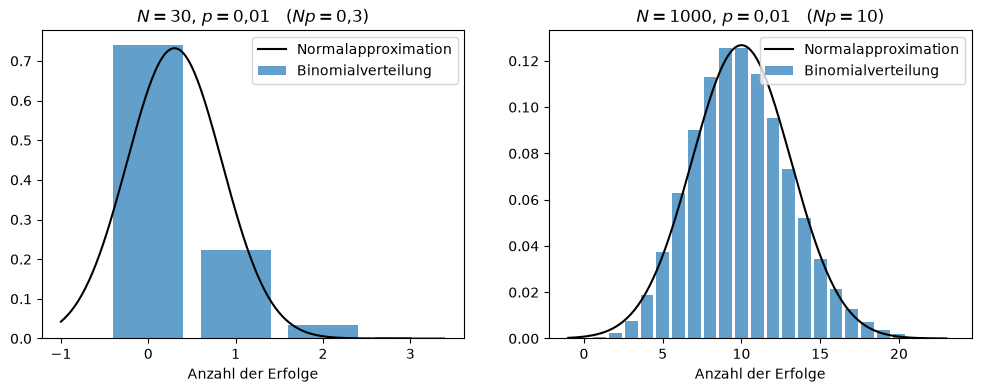

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for ax, n in ((ax1, 30), (ax2, 1000)):
    p = 0.01
    k = np.arange(0, int(n * p + 4 * np.sqrt(n * p * (1 - p))) + 2)
    ax.bar(k, binom(n, p).pmf(k), label="Binomialverteilung", alpha=0.7)
    xs = np.linspace(k.min() - 1, k.max(), 200)
    ax.plot(xs, norm(loc=n * p, scale=np.sqrt(n * p * (1 - p))).pdf(xs),
            color="black", label="Normalapproximation")
    np_text = f"{n * p:g}".replace(".", "{,}")
    ax.set_title(f"$N = {n}$, $p = 0{{,}}01$   ($Np = {np_text}$)")
    ax.set_xlabel("Anzahl der Erfolge")
    ax.legend()

plt.show()

Links, bei $N = 30$, liegt fast die ganze Wahrscheinlichkeitsmasse auf den Werten $0$ und $1$ — die Verteilung ist an der Null abgeschnitten und stark rechtsschief, während die Normalapproximation seelenruhig ins Negative läuft und dort Wahrscheinlichkeit verteilt, wo es gar keine Ergebnisse gibt. Rechts, bei $N = 1000$, ist die Laplace-Bedingung mit $Np = 10$ gerade erfüllt, und die Glockenform ist erkennbar.

Die Moral ist allgemeiner als das Beispiel: Eine Faustregel, die nur die Stichprobengröße nennt und nichts über die Verteilung sagt, kann nicht funktionieren. Was zählt, ist das Verhältnis aus Schiefe und Stichprobengröße.